# Can TabPFN-3.5 Compete With Traditional Machine Learning Models?
## Non-Brand Data comparison notebook

Compare the **base TabPFN-3.5 checkpoint**, Logistic Regression, Random Forest, and CatBoost on Breast Cancer Wisconsin (Diagnostic) and Wine. This notebook runs the actual models and saves every split's predictions, indices, metrics, timings, environment, and figures.

**Protocol:** five stratified 75/25 holdouts (seeds 42–46), shared indices for all four models, fixed settings chosen before seeing test results, no hyperparameter search. Balanced accuracy is the primary metric. The splits overlap, so their standard deviation is descriptive, not a confidence interval or a significance test. All four models are required to finish the recorded comparison.

**Runtime:** CPU only, four compute threads; constructor + fit + first full-test `predict_proba` are timed separately for fresh estimators. A separate warm-up exercises all four models before measurements. Timings include preprocessing and cached-weight loading but exclude imports, network download, metrics, and file writing. This is not a GPU speed benchmark. Inference is local; dataset rows are not uploaded. Initial license verification and weight download require network access.

The two small, complete numeric datasets do not test categorical features, missingness, text, temporal/group splits, large tables, or production serving. Scores are educational benchmark results, not evidence of medical suitability.

Run all cells in order. An internet connection is needed for package installation and the first checkpoint download. Review the [checkpoint license](https://huggingface.co/Prior-Labs/tabpfn_3_5/blob/main/LICENSE) before use. The package requires one-time license acceptance at https://ux.priorlabs.ai and a locally configured `TABPFN_TOKEN`. Do not put a token in the notebook. Never silently replace the requested version with an older model.

### 1. Install in a separate environment

Python 3.11 is used for the recorded run. Uncomment the cell below in a fresh Jupyter environment, install, then restart the kernel. For the exact direct dependency versions, use `requirements.txt` alongside this notebook. Installation is excluded from runtime results.

In [1]:
# %pip install -r requirements.txt

In [2]:
import os
from pathlib import Path
ROOT = Path.cwd()
OUT = ROOT / "results"
IMAGES = ROOT / "images"
for folder in [OUT, IMAGES, ROOT / ".model_cache"]:
    folder.mkdir(exist_ok=True)
os.environ["TABPFN_MODEL_CACHE_DIR"] = str(ROOT / ".model_cache")
os.environ["HF_HOME"] = str(ROOT / ".model_cache" / "huggingface")
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["TABPFN_DISABLE_TELEMETRY"] = "1"
os.environ["SKB_DATA_DIRECTORY"] = str(ROOT / ".model_cache" / "skrub")
ALLOW_PENDING_TABPFN = False  # Require all four models; never report an incomplete comparison as complete.
THREADS = 4
for key in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[key] = str(THREADS)

import gc, json, time, platform, hashlib, importlib.metadata as metadata
from datetime import datetime
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, log_loss
from threadpoolctl import threadpool_limits
from catboost import CatBoostClassifier
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion
from tabpfn.errors import TabPFNLicenseError
torch.set_num_threads(THREADS)
torch.set_num_interop_threads(1)

SEEDS = [42, 43, 44, 45, 46]
TEST_SIZE = 0.25
MODEL_NAMES = ["Logistic Regression", "Random Forest", "CatBoost", "TabPFN-3.5"]
CHECKPOINT = "tabpfn-v3.5-20260909.safetensors"
def processor_name():
    if platform.system() == "Windows":
        import winreg
        with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, "HARDWARE" + chr(92) + "DESCRIPTION" + chr(92) + "System" + chr(92) + "CentralProcessor" + chr(92) + "0") as key:
            return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
    return platform.processor()
environment = {
    "run_date_jakarta": datetime.now(ZoneInfo("Asia/Jakarta")).isoformat(),
    "python": platform.python_version(), "os": platform.platform(),
    "processor": processor_name(), "logical_cpu_count": os.cpu_count(),
    "threads": THREADS, "device": "cpu", "cuda_available": torch.cuda.is_available(),
    "checkpoint": CHECKPOINT, "seeds": SEEDS, "test_size": TEST_SIZE,
    "versions": {p: metadata.version(p) for p in ["tabpfn", "torch", "catboost", "scikit-learn", "numpy", "pandas", "scipy", "matplotlib", "nbformat", "nbclient", "ipykernel", "huggingface-hub", "safetensors", "skrub"]},
}
(OUT / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
display(pd.Series(environment["versions"], name="version").to_frame())
print("Device: CPU | compute threads:", THREADS)

,version
tabpfn,9.1.0
torch,2.14.1
catboost,1.2.10
scikit-learn,1.6.1
numpy,1.26.4
pandas,2.2.3
scipy,1.12.0
matplotlib,3.10.8
nbformat,5.10.4
nbclient,0.10.2


Device: CPU | compute threads: 4


### 2. Load both datasets

Breast Cancer: 569 rows, 30 numeric features, two classes (0 = malignant, 1 = benign). Wine: 178 rows, 13 numeric features, three cultivars. Source: [scikit-learn Breast Cancer loader](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html) and [Wine loader](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html).

No scaling or feature selection happens before splitting. Logistic Regression gets its own scaler fitted on the training rows inside a pipeline. Tree models and TabPFN receive the original numeric values.

In [3]:
datasets = {"Breast Cancer": load_breast_cancer(as_frame=True), "Wine": load_wine(as_frame=True)}
dataset_rows = []
for name, data in datasets.items():
    assert data.data.isna().sum().sum() == 0
    digest = hashlib.sha256(np.ascontiguousarray(data.data.to_numpy()).tobytes() + np.ascontiguousarray(data.target.to_numpy()).tobytes()).hexdigest()
    dataset_rows.append({"dataset": name, "rows": len(data.data), "features": data.data.shape[1], "classes": data.target.nunique(), "class_counts": data.target.value_counts().sort_index().to_dict(), "sha256_values": digest})
dataset_info = pd.DataFrame(dataset_rows)
dataset_info.to_json(OUT / "datasets.json", orient="records", indent=2)
display(dataset_info.drop(columns="sha256_values"))

,dataset,rows,features,classes,class_counts
0,Breast Cancer,569,30,2,"{0: 212, 1: 357}"
1,Wine,178,13,3,"{0: 59, 1: 71, 2: 48}"


### 3. Define the models before evaluation

These are fixed, untuned configurations. Random Forest uses 300 trees. CatBoost uses 500 boosting iterations, depth 6, and learning rate 0.05. Logistic Regression uses L2 regularization with C=1 and a 2,000-iteration limit. TabPFN uses four ensemble members and the base 3.5 checkpoint, not Fast, Plus, or Thinking. Four is an explicit compute choice, not a claim about the best ensemble size or the package default.

The estimator-count numbers do not represent equivalent units of work across algorithms. This compares practical fixed configurations, not equal compute budgets or each model's maximum attainable accuracy.

In [4]:
def make_model(name, seed):
    if name == "Logistic Regression":
        return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, solver="lbfgs", random_state=seed))
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=THREADS)
    if name == "CatBoost":
        return CatBoostClassifier(iterations=500, depth=6, learning_rate=0.05,
                                 random_seed=seed, thread_count=THREADS,
                                 verbose=False, allow_writing_files=False, task_type="CPU")
    if name == "TabPFN-3.5":
        return TabPFNClassifier.create_default_for_version(
            ModelVersion.V3_5, model_path=str(ROOT / ".model_cache" / CHECKPOINT),
            n_estimators=4, device="cpu", random_state=seed,
            n_preprocessing_jobs=1, show_progress_bar=False)
    raise ValueError(name)

settings = {name: make_model(name, 42).get_params(deep=False) for name in MODEL_NAMES}
(OUT / "model_settings.json").write_text(json.dumps(settings, indent=2, default=str), encoding="utf-8")
display(pd.DataFrame({"model": MODEL_NAMES, "settings": [str(settings[n]) for n in MODEL_NAMES]}))

,model,settings
0,Logistic Regression,"{'memory': None, 'steps': [('standardscaler', ..."
1,Random Forest,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
2,CatBoost,"{'iterations': 500, 'learning_rate': 0.05, 'de..."
3,TabPFN-3.5,"{'auto_scale_n_estimators': True, 'average_bef..."


### 4. Warm up separately

This cell downloads the checkpoint if absent. It fits a tiny, stratified subset and makes one prediction with each model. We record setup duration but do not mix it into the repeated benchmark. Every timed evaluation below still constructs a fresh estimator and includes its fit. Test labels are never passed to a model or used for configuration choices.

In [5]:
warm_data = datasets["Wine"]
warm_ix, _ = train_test_split(np.arange(len(warm_data.data)), train_size=36, stratify=warm_data.target, random_state=100)
warmups = []
available_models = MODEL_NAMES.copy()
model_status = {name: "measured" for name in MODEL_NAMES}
with threadpool_limits(limits=THREADS):
    for name in MODEL_NAMES:
        start = time.perf_counter()
        model = make_model(name, 100)
        try:
            model.fit(warm_data.data.iloc[warm_ix], warm_data.target.iloc[warm_ix])
            model.predict_proba(warm_data.data.iloc[warm_ix[:3]])
        except TabPFNLicenseError:
            if name != "TabPFN-3.5" or not ALLOW_PENDING_TABPFN:
                raise
            available_models.remove(name)
            model_status[name] = "pending: official weight download requires license acceptance and authentication"
            print("TabPFN-3.5 PENDING: enable licensed access and rerun. No TabPFN scores will be produced.")
            del model
            continue
        warmups.append({"model": name, "setup_seconds": time.perf_counter() - start})
        del model
        gc.collect()
pd.DataFrame(warmups).to_csv(OUT / "setup_timings.csv", index=False)
checkpoint_path = ROOT / ".model_cache" / CHECKPOINT
if "TabPFN-3.5" in available_models:
    assert checkpoint_path.is_file(), "Requested 3.5 checkpoint was not downloaded."
    digest = hashlib.sha256()
    with checkpoint_path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    environment["checkpoint_sha256"] = digest.hexdigest()
    environment["checkpoint_bytes"] = checkpoint_path.stat().st_size
environment["model_status"] = model_status
(OUT / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
display(pd.DataFrame(warmups))
print("Checkpoint:", CHECKPOINT)
print("Status:", model_status)
print("SHA256:", environment.get("checkpoint_sha256", "pending access; no weights downloaded"))

,model,setup_seconds
0,Logistic Regression,0.026024
1,Random Forest,0.456662
2,CatBoost,0.682624
3,TabPFN-3.5,0.936181


Checkpoint: tabpfn-v3.5-20260909.safetensors
Status: {'Logistic Regression': 'measured', 'Random Forest': 'measured', 'CatBoost': 'measured', 'TabPFN-3.5': 'measured'}
SHA256: ece4d67eadfea42eb0e610df5189bea60cb7f31073d81e9c7a019b76eacf0be3


### 5. Run the evaluations

Balanced accuracy averages recall across classes; macro F1 gives each class equal weight. ROC AUC uses class 1 (benign) as the positive class for Breast Cancer and macro one-vs-rest for Wine. Lower log loss is better; the other scores are better when higher.

All hard predictions use the class with maximum predicted probability. The first full-test `predict_proba` call is timed. Total seconds = construction + fit + prediction. It is a batch measurement, not single-row latency. Model order is deterministically shuffled on each split to reduce fixed-order bias. Individual rows are saved as soon as each evaluation completes. The full comparison has 40 evaluations; the baseline-only run has 30. Missing licensed access is explicitly recorded above; all other errors stop the run.

In [6]:
rows, split_indices = [], {}
for dataset_name, data in datasets.items():
    X, y = data.data, data.target
    for seed in SEEDS:
        train_ix, test_ix = train_test_split(np.arange(len(X)), test_size=TEST_SIZE, stratify=y, random_state=seed)
        assert not set(train_ix) & set(test_ix)
        split_indices[f"{dataset_name}_{seed}"] = {"train": train_ix.tolist(), "test": test_ix.tolist()}
        X_train, X_test = X.iloc[train_ix], X.iloc[test_ix]
        y_train, y_test = y.iloc[train_ix], y.iloc[test_ix]
        order = np.random.default_rng(seed).permutation(available_models)
        for name in order:
            gc.collect()
            with threadpool_limits(limits=THREADS):
                start = time.perf_counter()
                model = make_model(name, seed)
                constructed = time.perf_counter()
                model.fit(X_train, y_train)
                fitted = time.perf_counter()
                probabilities = model.predict_proba(X_test)
                predicted = time.perf_counter()
            classes = np.asarray(model.classes_)
            assert probabilities.shape == (len(test_ix), len(classes))
            assert np.isfinite(probabilities).all()
            assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-5)
            labels = classes[probabilities.argmax(axis=1)]
            auc = roc_auc_score(y_test, probabilities[:, 1]) if len(classes) == 2 else roc_auc_score(y_test, probabilities, labels=classes, multi_class="ovr", average="macro")
            row = {"dataset": dataset_name, "seed": seed, "model": name,
                   "n_train": len(train_ix), "n_test": len(test_ix),
                   "accuracy": accuracy_score(y_test, labels),
                   "balanced_accuracy": balanced_accuracy_score(y_test, labels),
                   "macro_f1": f1_score(y_test, labels, average="macro"),
                   "roc_auc": auc, "log_loss": log_loss(y_test, probabilities, labels=classes),
                   "construct_seconds": constructed-start, "fit_seconds": fitted-constructed,
                   "predict_seconds": predicted-fitted, "total_seconds": predicted-start}
            rows.append(row)
            pd.DataFrame(rows).to_csv(OUT / "per_split_results.csv", index=False)
            pred_frame = pd.DataFrame({"row_index": test_ix, "actual": y_test.to_numpy(), "prediction": labels})
            for col, cls in enumerate(classes):
                pred_frame[f"probability_class_{cls}"] = probabilities[:, col]
            stem = f"{dataset_name.lower().replace(' ', '_')}_{seed}_{name.lower().replace(' ', '_')}"
            pred_frame.to_csv(OUT / f"predictions_{stem}.csv", index=False)
            print(f"{dataset_name} | seed {seed} | {name}: BA={row['balanced_accuracy']:.4f}, total={row['total_seconds']:.3f}s", flush=True)
            del model
        (OUT / "split_indices.json").write_text(json.dumps(split_indices, indent=2), encoding="utf-8")
results = pd.DataFrame(rows)
assert len(results) == 2 * len(SEEDS) * len(available_models)
assert results.groupby(["dataset", "seed"])["model"].nunique().eq(len(available_models)).all()
display(results)

Breast Cancer | seed 42 | TabPFN-3.5: BA=0.9850, total=7.578s


Breast Cancer | seed 42 | CatBoost: BA=0.9567, total=2.637s


Breast Cancer | seed 42 | Random Forest: BA=0.9512, total=0.392s


Breast Cancer | seed 42 | Logistic Regression: BA=0.9850, total=0.046s


Breast Cancer | seed 43 | Random Forest: BA=0.9306, total=0.460s


...

Wine | seed 46 | Logistic Regression: BA=0.9815, total=0.005s


Wine | seed 46 | Random Forest: BA=0.9630, total=0.440s


Wine | seed 46 | CatBoost: BA=0.9630, total=0.973s


Wine | seed 46 | TabPFN-3.5: BA=0.9815, total=1.865s


,dataset,seed,model,n_train,n_test,accuracy,balanced_accuracy,macro_f1,roc_auc,log_loss,construct_seconds,fit_seconds,predict_seconds,total_seconds
0,Breast Cancer,42,TabPFN-3.5,426,143,0.986014,0.985010,0.985010,0.997275,0.067215,0.000086,0.254321,7.323237,7.577644
1,Breast Cancer,42,CatBoost,426,143,0.965035,0.956709,0.962067,0.997065,0.072815,0.008400,2.624766,0.004199,2.637366
2,Breast Cancer,42,Random Forest,426,143,0.958042,0.951153,0.954670,0.994864,0.104598,0.000024,0.345880,0.046283,0.392186
3,Breast Cancer,42,Logistic Regression,426,143,0.986014,0.985010,0.985010,0.997694,0.067869,0.000040,0.043541,0.002691,0.046272
4,Breast Cancer,43,Random Forest,426,143,0.937063,0.930608,0.932281,0.977149,0.171017,0.000024,0.412976,0.047175,0.460175
5,Breast Cancer,43,CatBoost,426,143,0.965035,0.960587,0.962378,0.981342,0.158599,0.000051,2.288911,0.001368,2.290330
6,Breast Cancer,43,Logistic Regression,426,143,0.965035,0.956709,0.962067,0.984067,0.132322,0.000032,0.007623,0.001398,0.009053
7,Breast Cancer,43,TabPFN-3.5,426,143,0.965035,0.960587,0.962378,0.985744,0.135692,0.000081,0.166415,7.041843,7.208338
8,Breast Cancer,44,Random Forest,426,143,0.979021,0.975577,0.977427,0.997275,0.083645,0.000043,0.692918,0.083538,0.776499
9,Breast Cancer,44,Logistic Regression,426,143,0.986014,0.988889,0.985123,1.000000,0.052677,0.000048,0.013848,0.002368,0.016263


### 6. Summarize performance and runtime

Scores are mean ± sample standard deviation over five splits. Runtime is the median of five observations. Rounded ties should not be treated as a ranking. A pairwise difference table below compares the same splits and remains descriptive because the test sets overlap.

In [7]:
metrics = ["accuracy", "balanced_accuracy", "macro_f1", "roc_auc", "log_loss"]
summary = results.groupby(["dataset", "model"])[metrics].agg(["mean", "std"])
summary.columns = ["_".join(c) for c in summary.columns]
timing = results.groupby(["dataset", "model"])[["construct_seconds", "fit_seconds", "predict_seconds", "total_seconds"]].median().add_suffix("_median")
summary = summary.join(timing).reset_index()
summary.to_csv(OUT / "summary.csv", index=False)
score_table = summary[["dataset", "model"]].copy()
for metric in metrics:
    score_table[metric] = summary.apply(lambda r: f"{r[metric+'_mean']:.4f} ± {r[metric+'_std']:.4f}", axis=1)
display(score_table)
display(summary[["dataset", "model", *timing.columns]].round(4))
if "TabPFN-3.5" in available_models:
    wide = results.pivot(index=["dataset", "seed"], columns="model", values="balanced_accuracy")
    deltas = wide.drop(columns="TabPFN-3.5").apply(lambda c: wide["TabPFN-3.5"] - c)
    deltas.to_csv(OUT / "paired_balanced_accuracy_deltas.csv")
    display(deltas.groupby(level="dataset").agg(["mean", "std"]))
else:
    print("TabPFN-3.5 performance and runtime: PENDING. No head-to-head verdict is possible.")

,dataset,model,accuracy,balanced_accuracy,macro_f1,roc_auc,log_loss
0,Breast Cancer,CatBoost,0.9720 ± 0.0099,0.9677 ± 0.0116,0.9699 ± 0.0107,0.9923 ± 0.0070,0.0940 ± 0.0426
1,Breast Cancer,Logistic Regression,0.9762 ± 0.0094,0.9734 ± 0.0134,0.9744 ± 0.0102,0.9939 ± 0.0066,0.0844 ± 0.0330
2,Breast Cancer,Random Forest,0.9594 ± 0.0152,0.9538 ± 0.0160,0.9563 ± 0.0163,0.9893 ± 0.0078,0.1200 ± 0.0323
3,Breast Cancer,TabPFN-3.5,0.9748 ± 0.0127,0.9722 ± 0.0139,0.9730 ± 0.0136,0.9944 ± 0.0054,0.0832 ± 0.0336
4,Wine,CatBoost,0.9689 ± 0.0253,0.9741 ± 0.0211,0.9698 ± 0.0256,0.9996 ± 0.0009,0.1017 ± 0.0342
5,Wine,Logistic Regression,0.9733 ± 0.0243,0.9759 ± 0.0203,0.9738 ± 0.0235,0.9996 ± 0.0007,0.0799 ± 0.0219
6,Wine,Random Forest,0.9778 ± 0.0222,0.9815 ± 0.0185,0.9785 ± 0.0219,0.9993 ± 0.0007,0.1436 ± 0.0216
7,Wine,TabPFN-3.5,0.9867 ± 0.0122,0.9889 ± 0.0101,0.9878 ± 0.0111,1.0000 ± 0.0000,0.0248 ± 0.0151


,dataset,model,construct_seconds_median,fit_seconds_median,predict_seconds_median,total_seconds_median
0,Breast Cancer,CatBoost,0.0001,2.3144,0.0016,2.3160
1,Breast Cancer,Logistic Regression,0.0000,0.0090,0.0014,0.0104
2,Breast Cancer,Random Forest,0.0000,0.4106,0.0475,0.4581
3,Breast Cancer,TabPFN-3.5,0.0001,0.1664,7.0418,7.2083
4,Wine,CatBoost,0.0001,0.9427,0.0011,0.9438
5,Wine,Logistic Regression,0.0000,0.0044,0.0010,0.0055
6,Wine,Random Forest,0.0000,0.3926,0.0376,0.4304
7,Wine,TabPFN-3.5,0.0001,0.2126,1.5809,1.7234


model          CatBoost           Logistic Regression           Random Forest  \
                   mean       std                mean       std          mean   
dataset                                                                         
Breast Cancer  0.004549  0.014054           -0.001111  0.009187      0.018428   
Wine           0.014815  0.015494            0.012963  0.018050      0.007407   

model                    
                    std  
dataset                  
Breast Cancer  0.014672  
Wine           0.010143

### 7. Figures for the article

Original figures generated from this notebook's saved measurements. Error bars show split standard deviation, not confidence intervals. Runtime uses a logarithmic axis because the models can differ by orders of magnitude.

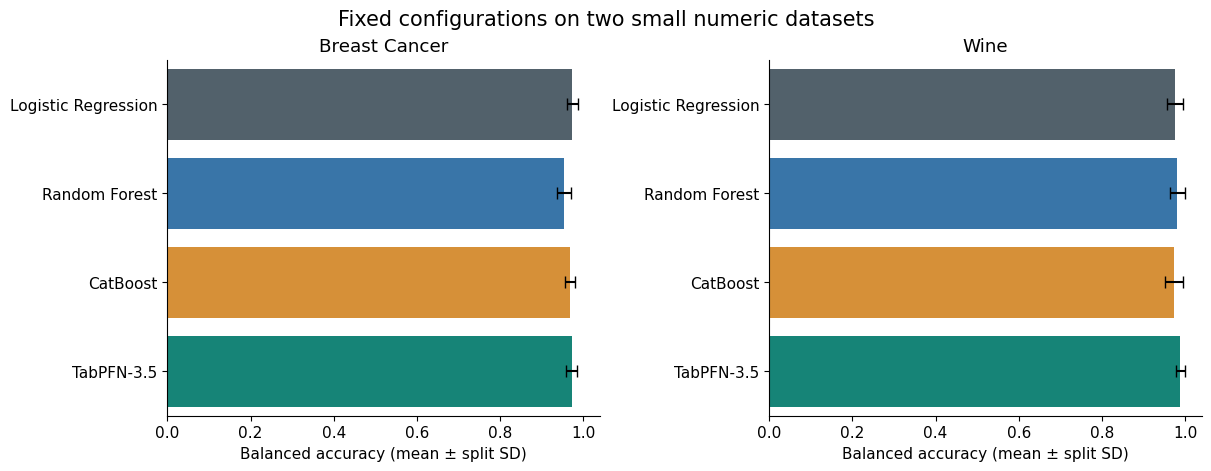

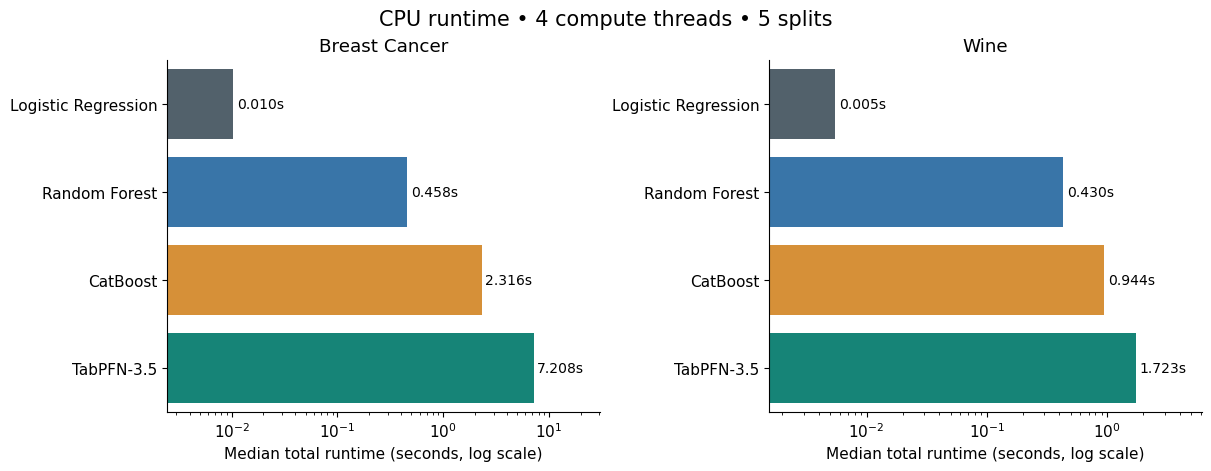

In [8]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
colors = ["#52616B", "#3975A8", "#D69038", "#168477"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
for ax, dataset_name in zip(axes, datasets):
    sub = summary[summary.dataset.eq(dataset_name)].set_index("model").reindex(MODEL_NAMES)
    ax.barh(MODEL_NAMES, sub.balanced_accuracy_mean, xerr=sub.balanced_accuracy_std, color=colors, capsize=4)
    if "TabPFN-3.5" not in available_models:
        ax.text(0.02, 3, "Pending licensed access", va="center", color="#168477")
    ax.set_xlim(0, 1.04)
    ax.set_xlabel("Balanced accuracy (mean ± split SD)")
    ax.set_title(dataset_name)
    ax.invert_yaxis()
    ax.set_ylim(3.5, -0.5)
fig.suptitle("Fixed configurations on two small numeric datasets", fontsize=15)
fig.savefig(IMAGES / "performance.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
for ax, dataset_name in zip(axes, datasets):
    sub = summary[summary.dataset.eq(dataset_name)].set_index("model").reindex(MODEL_NAMES)
    ax.barh(MODEL_NAMES, sub.total_seconds_median, color=colors)
    ax.set_xscale("log")
    ax.set_xlabel("Median total runtime (seconds, log scale)")
    ax.set_title(dataset_name)
    ax.invert_yaxis()
    ax.set_ylim(3.5, -0.5)
    ax.margins(x=0.22)
    for i, val in enumerate(sub.total_seconds_median):
        if np.isfinite(val):
            ax.text(val*1.08, i, f"{val:.3f}s", va="center", fontsize=10)
    if "TabPFN-3.5" not in available_models:
        ax.text(0.03, 3, "Pending licensed access", transform=ax.get_yaxis_transform(), va="center", color="#168477")
fig.suptitle("CPU runtime • 4 compute threads • 5 splits", fontsize=15)
fig.savefig(IMAGES / "runtime.png", dpi=200, bbox_inches="tight")
plt.show()

### 8. What this experiment can and cannot answer

Use the tables to compare the four fixed configurations on these two datasets and this CPU. Do not infer that any model wins all tabular tasks, or that CPU timing predicts GPU timing. Small test sets can change rankings with a few mistakes. There is no tuning budget, memory profiling, single-request latency test, fairness audit, or categorical-feature evaluation here.

To extend the study, predeclare a new dataset and split strategy, then tune inside each training partition with an equal, recorded search budget. Never tune using these test labels. For time-ordered or grouped records, replace random holdouts with an appropriate temporal or group split.

**References**
- [TabPFN-3.5 technical report and release](https://priorlabs.ai/technical-reports/tabpfn-3-5)
- [Base checkpoint and model card](https://huggingface.co/Prior-Labs/tabpfn_3_5)
- [TabPFN implementation](https://github.com/PriorLabs/TabPFN)
- [Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
- [CatBoostClassifier](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier)

**Picture credits:** performance and runtime charts are original Non-Brand Data figures generated by this notebook. The article's screenshots capture this executed notebook's HTML export. `images/PICTURE_REFERENCES.md` records filenames, captions, source URLs, and provenance. No vendor benchmark chart is presented as our own result.